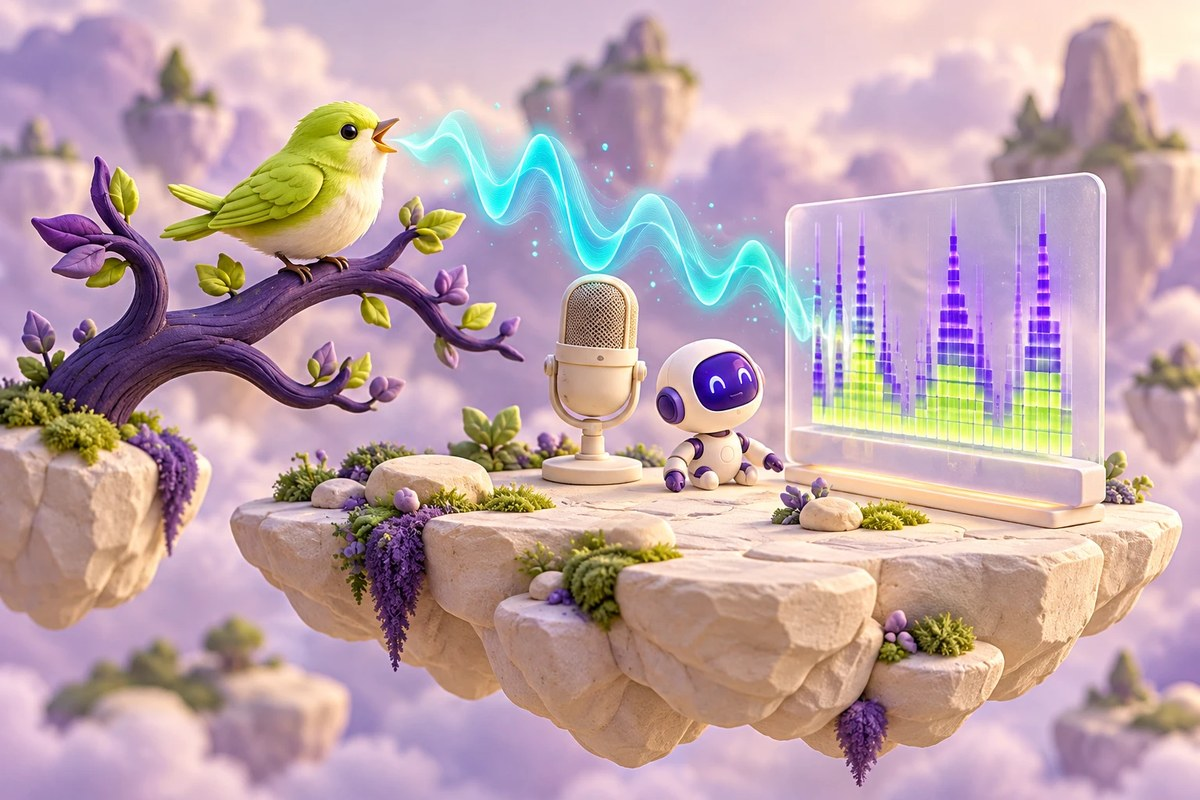

AI PATH · Аудио и сигналы · Урок 002

# Сигналы: гармоники, спектр и автокорреляция

Переход от синусоиды к FFT на синтетике, аудио и временном ряде

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-002-goal"></a>
## Что вы разберёте

Научиться связывать амплитуду, частоту и фазу с отсчётами и спектральными компонентами, проверяя единицы осей.

### Перед началом

- Синус, косинус и радианы
- Массивы и функции Python
- Частота дискретизации

### Что понадобится

- NumPy, Matplotlib, SciPy, Librosa и Pandas
- IPython для inline-графиков
- Пример аудио через старый librosa.example_audio_file
- Для последнего блока: Colab и Drive, traff.csv и столбец «22,226.00»

## Навигация по уроку

- [Цель и подготовка](#ai-002-goal)
- [Карта урока](#ai-002-map)
- [Сложить гармоники](#ai-002-section-01)
- [Отделить амплитуду от фазы](#ai-002-section-02)
- [Различить отсчёты и квантование](#ai-002-section-03)
- [Посмотреть спектр аудио](#ai-002-section-04)
- [Прочитать амплитуду и фазу FFT](#ai-002-section-05)
- [Восстановить составной сигнал](#ai-002-section-06)
- [Исследовать автокорреляцию](#ai-002-section-07)
- [Перенести приём на трафик](#ai-002-section-08)
- [Проверьте понимание](#ai-002-practice)
- [Источники и ограничения](#ai-002-provenance)

<a id="ai-002-map"></a>
## Карта урока

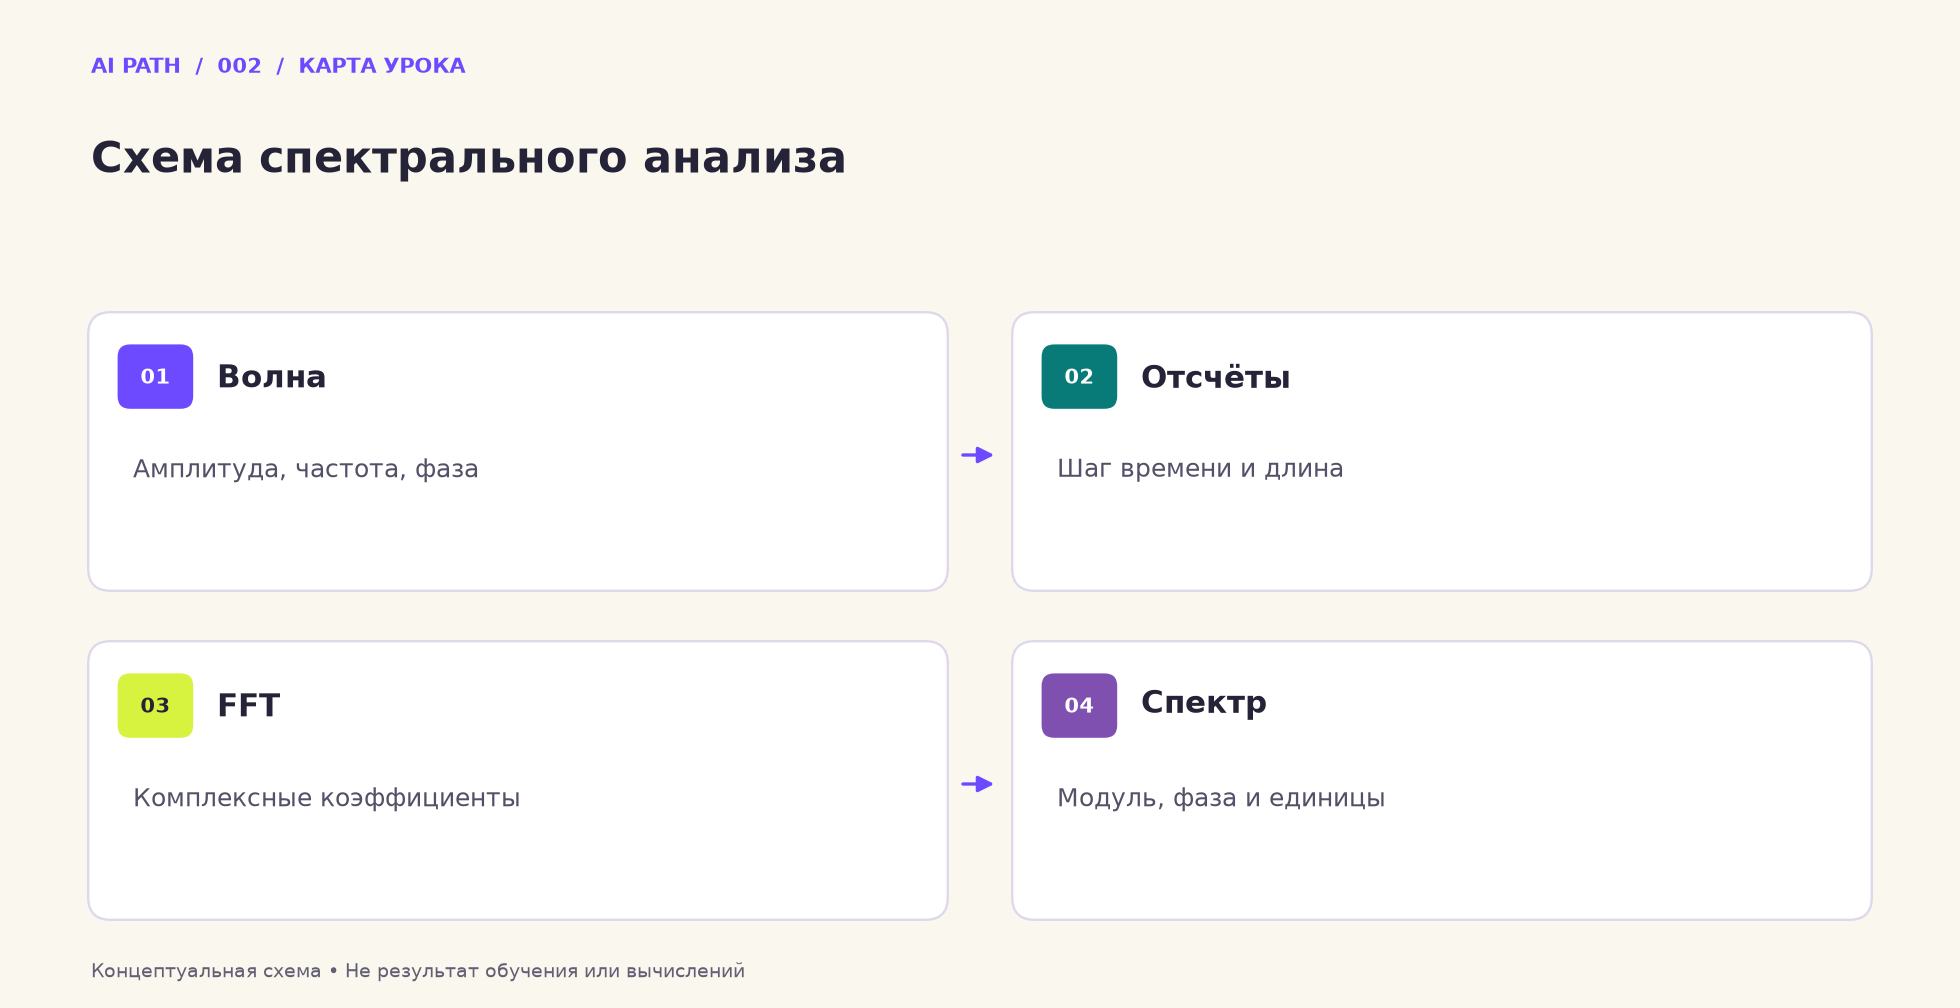

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Волна** — Амплитуда, частота, фаза
2. **Отсчёты** — Шаг времени и длина
3. **FFT** — Комплексные коэффициенты
4. **Спектр** — Модуль, фаза и единицы

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%9E%D0%B1%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BA%D0%B0_%D1%81%D0%B8%D0%B3%D0%BD%D0%B0%D0%BB%D0%BE%D0%B2%22%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Light**

Задание 1:

Переписать функцию Sine , таким образом, чтобы на выходе получать сигнал косинуса вместо синуса (np.cos)


















<a id="ai-002-section-01"></a>
## 01 · Сложить гармоники

Начните с одной косинусоиды и суммы нескольких волн. Сопоставьте параметры функции с изменениями формы сигнала.

_Далее — исходные ячейки учебного материала._

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

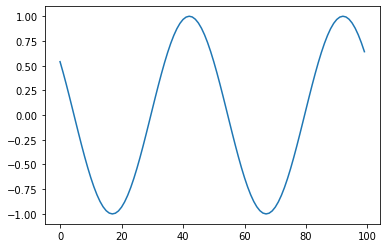

In [ ]:
def Cos(A, f, phi, fs, t, N):
    '''
    Inputs:
    A  = Амплитуда сигнала
    f  = Частота сигнала  Hz
    phi  = Начальная фаза синусоиды "Радианы"
    fs = Частота семплирования Hz
    t  = Число вместо 1, для лучшей визуализации графиков
    N  = Длина сигнала

    Output:
    x (numpy array)
    
    '''
    T = t/fs   # Период семплирования
    n = np.arange(N) # Кол-во семплов
    x = A*np.cos(2*np.pi*f*n*T + phi)
    return x

A = 1.0     
f = 10.0    
phi = 1.0   
fs = 50.0   
t = 0.1     

plt.plot(Cos(A, f, phi, fs, t, 100))

Задание 2:

Модифицировать функцию Sine таким образом чтобы можно было возвращать составной сигнал - состоящий из комбинаций sin и cos, каждая отдельная гармоническая функция в составном сигнале должна принимать свои параметры:

 A  = Амплитуда сигнала
 
 f  = Частота сигнала  Hz

 phi  = Начальная фаза синусоиды "Радианы"

 Сделайте вариант с 2-мя и 3-мя гармоническими сигналами

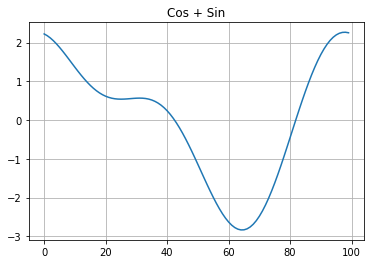

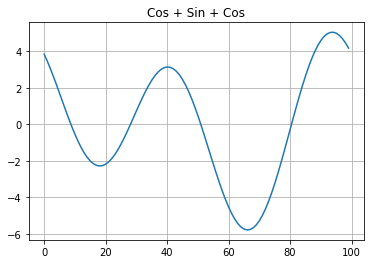

In [ ]:
def Cos_sin( **kwargs):
    '''
    Inputs:
    A  = Амплитуда сигнала
    f  = Частота сигнала  Hz
    phi  = Начальная фаза синусоиды "Радианы"
    fs = Частота семплирования Hz
    t  = Число вместо 1, для лучшей визуализации графиков
    N  = Длина сигнала

    Outputs:
    x1, x2 (numpy array)

    '''
    t = kwargs['t']
    fs = kwargs['fs']
    N = kwargs['N']
    T = t/fs         # Период семплирования
    n = np.arange(N) # Кол-во семплов

    # Вариант с двумя гармоническмим сигналами
    x1 = kwargs['A1']*np.cos(2*np.pi*kwargs['f1']*n*T + kwargs['phi1']) +\
         kwargs['A2']*np.sin(2*np.pi*kwargs['f2']*n*T + kwargs['phi2'])

    # Вариант с тремя гармоническмим сигналами
    x2 = kwargs['A1']*np.cos(2*np.pi*kwargs['f1']*n*T + kwargs['phi1']) +\
         kwargs['A2']*np.sin(2*np.pi*kwargs['f2']*n*T + kwargs['phi2']) +\
         kwargs['A3']*np.cos(2*np.pi*kwargs['f3']*n*T + kwargs['phi3'])
    return x1, x2

# Составляем функцию. На выходе будут 2 сигнала.
sig1, sig2 = Cos_sin(fs=50., t=0.1, N=100, A1=1, A2=2, A3=3, f1=10, f2=5, f3=10, phi1=1, phi2=1, phi3=1)

# Строим графики
plt.plot(sig1)
plt.title('Cos + Sin')
plt.grid(True, which='both')
plt.show()

plt.plot(sig2)
plt.title('Cos + Sin + Cos')
plt.grid(True, which='both')
plt.show()

<a id="ai-002-section-02"></a>
## 02 · Отделить амплитуду от фазы

Меняйте по одному параметру. Вертикальное растяжение и горизонтальный сдвиг отражают разные свойства сигнала.

_Далее — исходные ячейки учебного материала._

Задание 3:

Дан сигнал 3*np.sin(2*np.pi*5.*45*0.002 + 2.) Перепишите выражение таким образом, чтобы:
а) амплитуда увеличилась в 2 раза
б) Фаза сигнала была в 0.

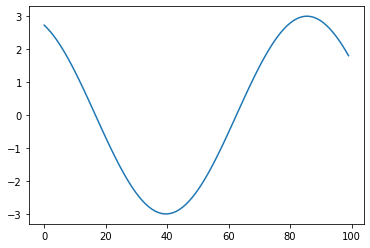

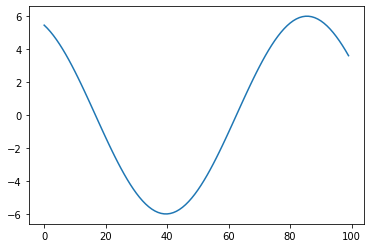

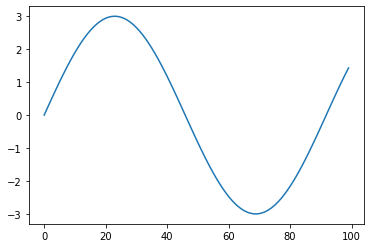

In [ ]:
# Переписываем уравнение для определение сигнала, добавляя колличество отсчетов 
# на которых мы берем сигнал, например 100: np.arange(100)

x_orig = 3*np.sin(2*np.pi*5.45*0.002*np.arange(100) + 2.)
x_a = 2*3*np.sin(2*np.pi*5.45*0.002*np.arange(100)  + 2.) # Амплитуда это множитель к сигналу, просто увеличиваем его на 2
x_b = 3*np.sin(2*np.pi*5.45*0.002*np.arange(100)  + 0.)   # Фаза это слагаемое к формуле сигнала, ставим ее в 0.

# Строим графики
plt.plot(x_orig)
plt.show()
plt.plot(x_a)
plt.show()
plt.plot(x_b)
plt.show()

<a id="ai-002-section-03"></a>
## 03 · Различить отсчёты и квантование

plot, stem и step по-разному рисуют один массив. Ступенчатое изображение само по себе не округляет амплитуды до уровней квантования.

_Далее — исходные ячейки учебного материала._

Задание 4:

Сигнал задан следующей функцией:
t = np.linspace(0, 1, n, endpoint=True)
np.sin(3*np.pi*t) + np.sin(5*np.pi*t)
Отобразить на графике Аналоговый, Дискретный и Квантованные сигналы

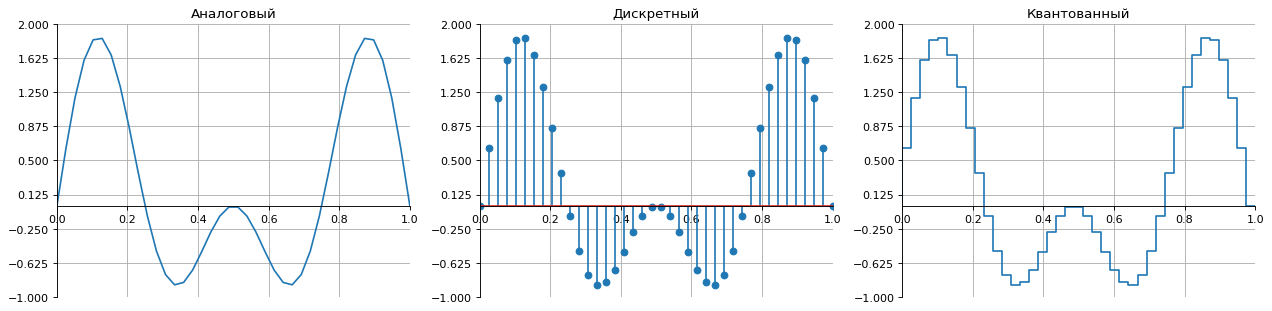

In [ ]:
import matplotlib.pyplot as plt

# Задаем количество сэмплов
n = 40

# Задаем вектор времени
t = np.linspace(0, 1, n, endpoint=True)

# Функция wive
x = np.sin(3*np.pi*t) + np.sin(5*np.pi*t)

# Функция выбора графиков
def plt_sel(s, *args, **kwargs):
    if s == 0:
        return plt.plot(*args)
    if s == 1:
        return plt.stem(*args, **kwargs)
    if s == 2:
        return plt.step(*args)

# Подписи для графиков
t_titles = ['Аналоговый', 'Дискретный', 'Квантованный']

# Строим графики
fig = plt.figure(figsize=(16, 4), dpi=80)
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.title(t_titles[i]) 
    plt_sel(i, t, x, use_line_collection=True)
    plt.xlim([0, 1])
    plt.yticks(np.linspace(np.floor(np.min(x)), np.ceil(np.max(x)), 9))
    plt.grid(True)
    
    # Добавляем отображение оси x
    ax = plt.gca()
    ax.spines['right'].set_color('none')
    ax.spines['top'].set_color('none')
    ax.spines['bottom'].set_position(('data',0))
plt.tight_layout()

<a id="ai-002-section-04"></a>
## 04 · Посмотреть спектр аудио

После загрузки звука сопоставьте длину массива, частоту дискретизации и масштаб FFT. Номер спектрального бина ещё не равен частоте в герцах.

_Далее — исходные ячейки учебного материала._

Задание 5:

Загрузите любой аудио сигнал и сделайте его Фурье преобразование. Выведите на графике амплитудный спектр.

In [ ]:
from scipy.fftpack import fft
import librosa
import librosa.display

# Загружаем пример аудио файла
filename = librosa.util.example_audio_file()
y, sr = librosa.load(filename)

In [ ]:
len(y)

1355168

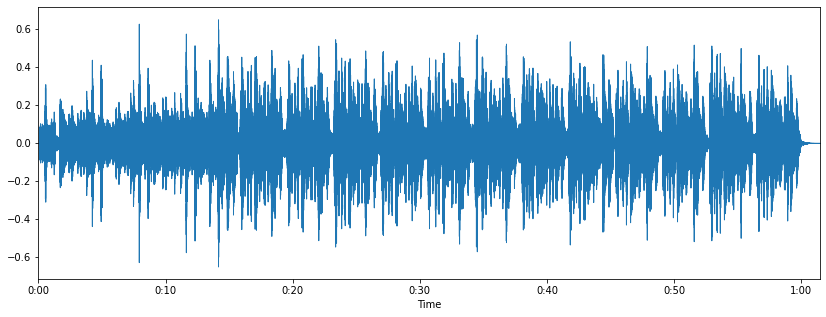

In [ ]:
# Выводим сигнал на экран
plt.figure(figsize=(14, 5))
librosa.display.waveplot(y, sr=sr)
plt.show()

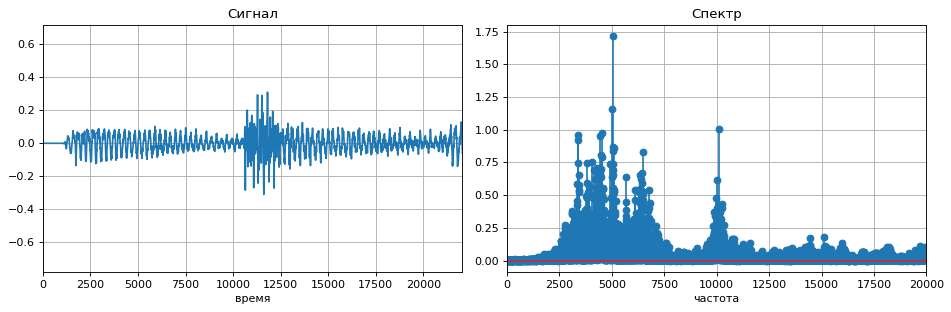

In [ ]:
# Зададим количество отсчетов
N = sr 

# Расчитываем FFT
X = fft(y)

# Выводим амплитудную характеристику, нормализуем по N
X = 2 * np.abs(X)/N 

# Выводим результаты
fig = plt.figure(figsize=(12, 4), dpi=80)

# Сигнал
plt.subplot(1, 2, 1)
plt.title('Сигнал')
plt.plot(y)
plt.xlim([0, N-1])
plt.xlabel('время')
plt.grid()

# Амплитудный спектр
plt.subplot(1, 2, 2)
plt.title('Спектр')
plt.stem(X, use_line_collection=True, basefmt='C3') #use_line_collection=True - способ хранения линий (для оптимизации памяти)
plt.xlim([0, 20000])
plt.xlabel('частота')
plt.grid()
plt.tight_layout()

<a id="ai-002-section-05"></a>
## 05 · Прочитать амплитуду и фазу FFT

На известной гармонике удобнее проверять формулы масштаба и фазового угла, чем на сложной записи.

_Далее — исходные ячейки учебного материала._

Задача 6:

Найдите модуль и аргумент спектра для следующего гармонического сигнала: синус (np.sin) С Частотой 20Гц Амплитудой 3 И фазой 1

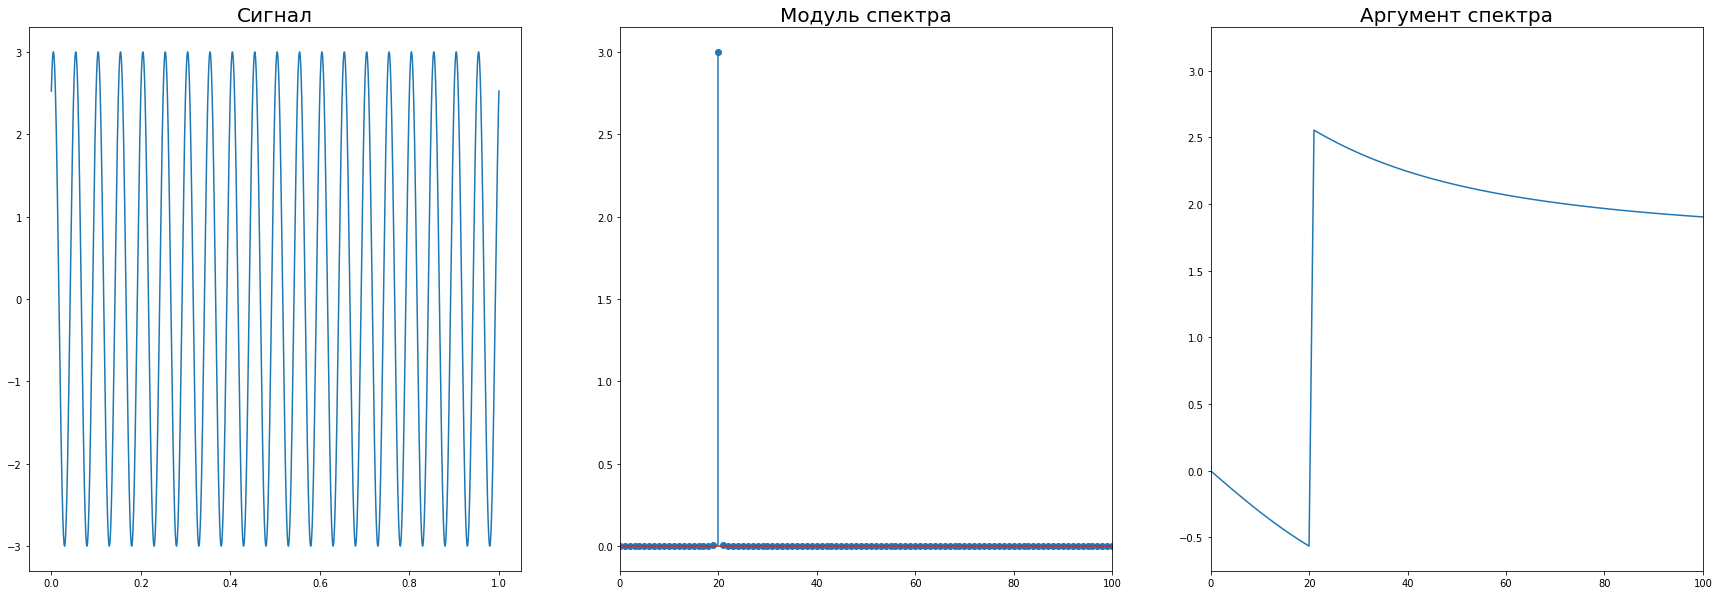

In [ ]:
'''
   Модуль спектра называют двусторонним спектром амплитуд(амплитудный спектр)
   или АЧХ - амплитудно-частотной характеристикой сигнала, а аргумент спектра
   - двусторонним спектром фаз(фазовый спектр) или ФЧХ – фазово-частотной
   характеристикой.

'''
# Зададим количество отсчетов
N = 10000 

# Зададим вектор времени
t = np.linspace(0, 1, N)

# Зададим Амплитуды и Частоты
f = 20
A =  3

# Цифровой сигнал
x = A * np.sin(2*np.pi*f*t+1) 

# Создаем 3 subplots
fig, ax = plt.subplots(1, 3, figsize=(30,10))
ax[0].plot(t, x)
ax[0].set_title('Сигнал', fontdict={'fontsize': 20})

# Выводим модуль спектра
a_f = np.fft.rfft(x)*2/N
ax[1].stem(abs(a_f), use_line_collection=True)
ax[1].set_xlim(0, 100)
ax[1].set_title('Модуль спектра', fontdict={'fontsize': 20})

# Выводим аргумент спектра
ax[2].plot(np.angle(a_f))
ax[2].set_xlim(0,100)
ax[2].set_title('Аргумент спектра', fontdict={'fontsize': 20})
plt.show()

In [ ]:
a_f

array([ 5.04882591e-04+0.00000000e+00j,  5.06152778e-04-1.60888349e-05j,
        5.10001823e-04-3.24213876e-05j, ...,
       -2.03712224e-06+1.26743538e-09j, -2.03712223e-06+6.33717581e-10j,
       -2.03712223e-06+0.00000000e+00j])

In [ ]:
d = 5.10001823e-04-3.24213876e-05j
np.angle(d)

-0.06348569166029883

**PRO**


<a id="ai-002-section-06"></a>
## 06 · Восстановить составной сигнал

Сравните спектр короткой последовательности и синтез суммы четырёх гармоник. Проверяйте соответствие частот индексам FFT.

_Далее — исходные ячейки учебного материала._

Задача 1:

Найдите модуль спектра для следующего сигнала [5,3,0,0,0,-1,3, 3, 5, 0].


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:24: UserWarning: In Matplotlib 3.3 individual lines on a stem plot will be added as a LineCollection instead of individual lines. This significantly improves the performance of a stem plot. To remove this warning and switch to the new behaviour, set the "use_line_collection" keyword argument to True.


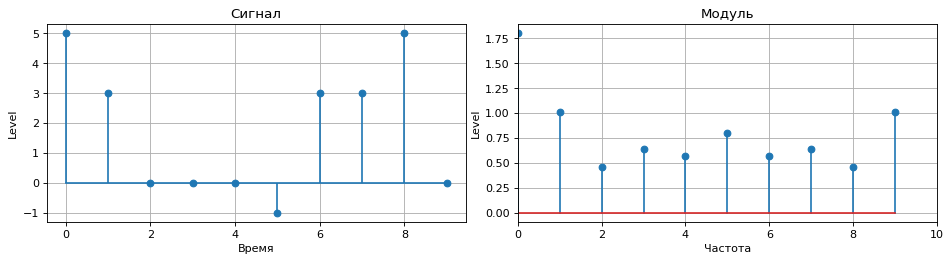

In [ ]:
# Цифровой сигнал
x = np.array([5,3,0,0,0,-1,3,3,5,0])

#  FFT на 20 отсчетах
N = 20

# Модуль спектра
xA = np.abs(fft(x))*2/N

# Список графиков
xT = [x, xA]
lst_title = ['Сигнал', u'Модуль']

# Выводим результаты
fig = plt.figure(figsize=(12, 6), dpi=80)
for i, sig in enumerate(xT):
    plt.subplot(2, 2, int(2**i))
    plt.ylabel('Level')
    plt.title(lst_title[i])
    if i == 0:
        plt.stem(sig, use_line_collection=True, basefmt='C0')
        plt.xlabel('Время')
    else:
        plt.stem(sig)
        plt.xlabel('Частота')
        plt.xlim([0, N//2])
    plt.grid()
plt.tight_layout()

Задача 2:

Дан сложный сигнал состоящий из 4-х гармонических компонент (синус) с различными значениями амплитуд и частот. Выведите спектр сигнала, на основе спектра определите частоты и амплитуды гармонических составляющих

сигнал (50 отсчетов): [ 0.00000000e+00, 6.61225969e+00, 3.25848078e+00, -1.20084548e+00, 3.45301249e+00, 8.94406332e+00, 4.69738850e+00, -1.36112077e+00, 2.18739790e+00, 8.35228095e+00, 5.25735866e+00, -1.07697134e+00, 1.30202985e+00, 6.87594476e+00, 3.25150704e+00, -4.69190350e+00, -3.88118391e+00, 2.10527395e+00, 3.66950398e-01, -6.14121684e+00, -4.38906614e+00, 3.21326193e+00, 3.07651304e+00, -3.62470149e+00, -3.41879558e+00, 3.41879558e+00, 3.62470149e+00, -3.07651304e+00, -3.21326193e+00, 4.38906614e+00, 6.14121684e+00, -3.66950398e-01, -2.10527395e+00, 3.88118391e+00, 4.69190350e+00, -3.25150704e+00, -6.87594476e+00, -1.30202985e+00, 1.07697134e+00, -5.25735866e+00, -8.35228095e+00, -2.18739790e+00, 1.36112077e+00, -4.69738850e+00, -8.94406332e+00, -3.45301249e+00, 1.20084548e+00, -3.25848078e+00, -6.61225969e+00, -1.78798433e-14]

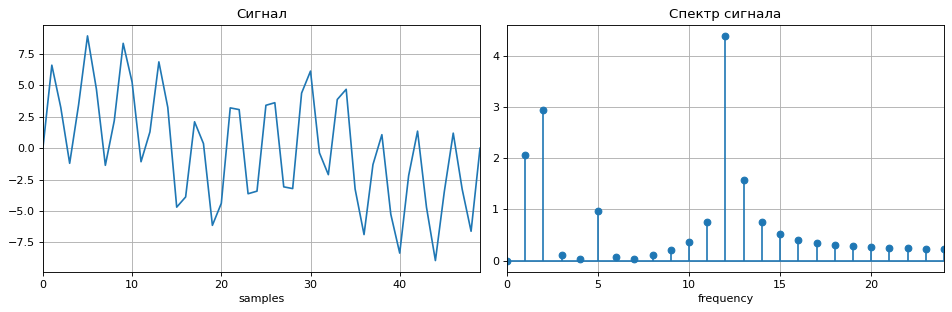

In [ ]:
N = 50 # Зададим количество отсчетов
t = np.linspace(0, 1, N)

# Занесем сигнал(50 отсчетов) в массив
x = np.array([ 0.00000000e+00, 6.61225969e+00, 3.25848078e+00, -1.20084548e+00, 3.45301249e+00, 8.94406332e+00, 4.69738850e+00, -1.36112077e+00, 2.18739790e+00, 8.35228095e+00, 5.25735866e+00, -1.07697134e+00, 1.30202985e+00, 6.87594476e+00, 3.25150704e+00, -4.69190350e+00, -3.88118391e+00, 2.10527395e+00, 3.66950398e-01, -6.14121684e+00, -4.38906614e+00, 3.21326193e+00, 3.07651304e+00, -3.62470149e+00, -3.41879558e+00, 3.41879558e+00, 3.62470149e+00, -3.07651304e+00, -3.21326193e+00, 4.38906614e+00, 6.14121684e+00, -3.66950398e-01, -2.10527395e+00, 3.88118391e+00, 4.69190350e+00, -3.25150704e+00, -6.87594476e+00, -1.30202985e+00, 1.07697134e+00, -5.25735866e+00, -8.35228095e+00, -2.18739790e+00, 1.36112077e+00, -4.69738850e+00, -8.94406332e+00, -3.45301249e+00, 1.20084548e+00, -3.25848078e+00, -6.61225969e+00, -1.78798433e-14])

# Расчитываем  FFT
X = fft(x)

# Выводим амплитудную характеристику, нормализуем по N
X = 2*np.abs(X) / N 

# Выводим результаты
fig = plt.figure(figsize=(12, 4), dpi=80)

# Сигнал
plt.subplot(1, 2, 1)
plt.title('Сигнал')
plt.plot(x)
plt.xlim([0, N-1])
plt.xlabel('samples')
plt.grid()

# Частотный спектр
plt.subplot(1, 2, 2)
plt.title('Спектр сигнала')
plt.stem(X, use_line_collection=True, basefmt='C0')
plt.xlim([0, N//2-1])
plt.xlabel('frequency')
plt.grid()
plt.tight_layout()

# На получившемся спектре ясно видны 4 пика соответствующие амплитудам составляющих 
# сигнал грамонических компонент, расположение пиков на оси x соответствует частотам гармонических компонент

In [ ]:
# Частоты гармонических составляющих равны
f = [1, 2, 5, 12]
f = np.array(f)

# Амплитуды гармонических составляющих
A = X[f]

print(A)
print(f)

[2.07634431 2.9506802  0.97511873 4.39890459]
[ 1  2  5 12]


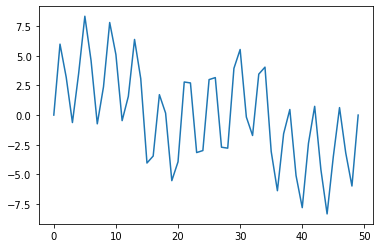

In [ ]:
plt.plot(np.sum(A*np.sin(2*np.pi*f*(t[None].T)), axis=1))

<a id="ai-002-section-07"></a>
## 07 · Исследовать автокорреляцию

Прямоугольный импульс помогает увидеть сходство сигнала с его сдвинутой копией и найти положение нулевого лага.

_Далее — исходные ячейки учебного материала._

Задача 3:

Самостоятельно ознакомившись с тем что такое Автокорреляционная функция рассчитать и отобразить графически Автокорреляционную функцию прямоугольного импульса: [np.zeros(8), np.ones(3), np.zeros(8)] , Напишите функцию вычисляющую автокорреляцию.

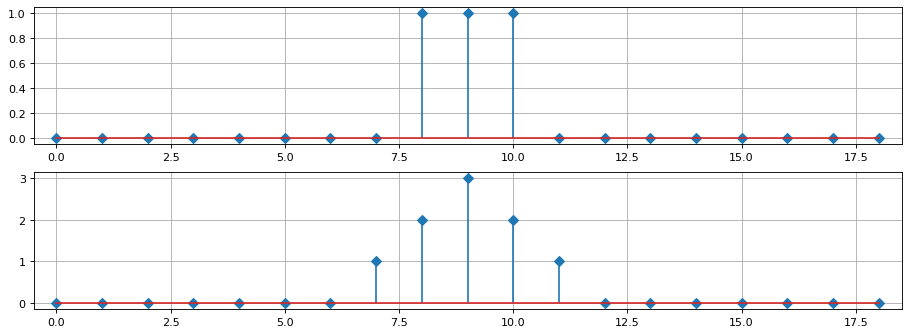

In [ ]:
'''
   Автокорреляционная функция  показывает зависимость между сигналом и его 
   копией, сдвинутой по времени.

   Автокорреляционная функция помогает находить повторяющиеся участки во 
   временной последовательности, с её помощью можно находить несущую частоту 
   сигнала.

   Физический смысл АКФ это энергия сигнала. 

'''

# Так как автокорреляция это просто свертка сигнала с самим собой - напишем простую функцию:
def auto_corr(x):
    res = np.correlate(x, x, mode='same') # np.correlate - вычисление свертки
    return res 

# Сигнал
x = np.concatenate([np.zeros(8), np.ones(3), np.zeros(8)])

# Полная функция автокорреляции(ACF)
cfx = auto_corr(x)

xl = [x, cfx]

# Строим графики
plt.figure(figsize=(14, 5), dpi=80)
for i in range(2):
    plt.subplot(2, 1, i+1)
    plt.stem(xl[i], linefmt='C0', markerfmt='D', use_line_collection=True)
    plt.grid(True)
    plt.xlim([-0.5, x.size-0.5])

<a id="ai-002-section-08"></a>
## 08 · Перенести приём на трафик

Последний блок очищает числовую колонку CSV и строит спектральные представления. Единицы времени ряда нужно задать отдельно от аудионастроек Librosa.

_Далее — исходные ячейки учебного материала._

Задача 4:

Попробуйте подобрать другой тип сигнала (например, ЭКГ, временной ряд и т.д.) и сделать его преобразование Фурье. Выведите его спектрограмму и полученный после преобразования амплитудный спектр



In [ ]:
from google.colab import drive # Импортируем гугл диск
drive.mount('./drive')

Go to this URL in a browser: https://accounts.google.com/o/oauth2/auth?client_id=947318989803-6bn6qk8qdgf4n4g3pfee6491hc0brc4i.apps.googleusercontent.com&redirect_uri=urn%3aietf%3awg%3aoauth%3a2.0%3aoob&response_type=code&scope=email%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdocs.test%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive.photos.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fpeopleapi.readonly

Enter your authorization code:
··········
Mounted at ./drive


In [ ]:
import pandas as pd

path = './drive/My Drive/Базы/traff.csv'                # Берем базу с количеством посещений сайта
series = pd.read_csv(path, dtype='string')['22,226.00'] # Берем второй столбец
series = series.str.replace(',', '')                    # Убираем запятые
series.head(20)

0     29593.00
1     31726.00
2     32684.00
3     31820.00
4     29354.00
5     29139.00
6     31244.00
7     32690.00
8     31299.00
9     29738.00
10    29400.00
11    27039.00
12    28251.00
13    30270.00
14    30152.00
15    28751.00
16    27668.00
17    27375.00
18    26558.00
19    28214.00
Name: 22,226.00, dtype: string

In [ ]:
# Преобразуем в массив с типом float
x = np.array(series).astype(float)

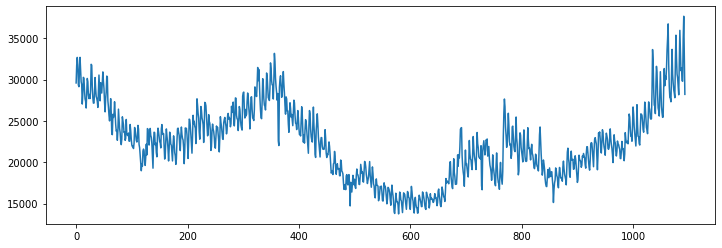

In [ ]:
# Строим график
plt.figure(figsize=(12, 4))
plt.plot(x)
plt.show()

In [ ]:
x = x - np.mean(x) # Вычитаем среднее (для наглядности графика)

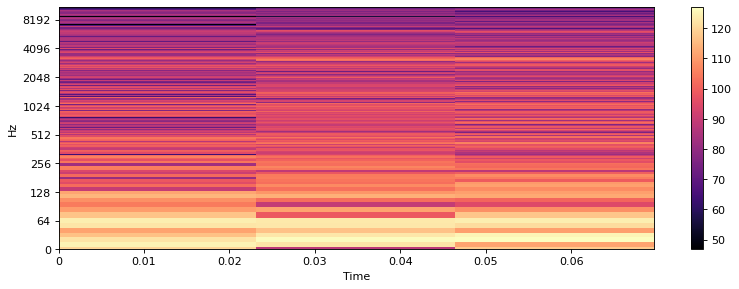

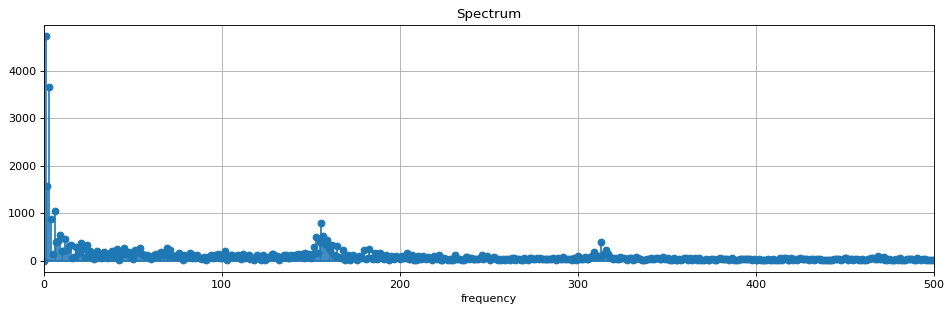

In [ ]:
# Расчитываем  FFT
N = 1000
X = fft(x)
X = 2*np.abs(X) / N # Выводим амплитудную характеристику, нормализуем по N

# Спектрограмма
fig = plt.figure(figsize=(12, 4), dpi=80)
X_spec = librosa.stft(x)
librosa.display.specshow(librosa.amplitude_to_db(abs(X_spec)), x_axis='time', y_axis='log')
plt.colorbar()
plt.show()

# Частотный спектр
fig = plt.figure(figsize=(12, 4), dpi=80)
plt.title('Spectrum')
plt.stem(X, use_line_collection=True, basefmt='C0')
plt.xlim([0, N/2])
plt.xlabel('frequency')
plt.grid()
plt.tight_layout()

<a id="ai-002-practice"></a>
## Проверьте понимание

1. Выведите частоту бина через частоту дискретизации и число отсчётов.
2. Объясните различие между графиком step и настоящим квантованием амплитуды.
3. Проверьте, что подписи времени и частоты подходят именно к ряду трафика.

### Один самостоятельный эксперимент

Для суммы двух известных гармоник измените только одну частоту и сравните спектральные пики до и после.

**Критерий успеха:** Положение пиков объяснено через шаг частот FFT; нормировочный множитель связан с фактической длиной преобразования.

<a id="ai-002-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/AudioNet/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%9E%D0%B1%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BA%D0%B0_%D1%81%D0%B8%D0%B3%D0%BD%D0%B0%D0%BB%D0%BE%D0%B2%22%22.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Старые функции Librosa example_audio_file/waveplot и параметр stem(use_line_collection) могут потребовать совместимого окружения.
- В нескольких блоках нормировка N не совпадает с длиной переданного FFT массива; N=20 не выполняет дополнение нулями само по себе.
- traff.csv отсутствует среди входов ноутбука; временной шаг ряда не задан для корректной интерпретации спектра.
- График ступеней иллюстрирует отображение отсчётов, а не выполненное квантование.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.